# Candidates

In [5]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import seaborn as sns

In [10]:
df = pd.read_csv("data/candidates/raw_counts.csv")

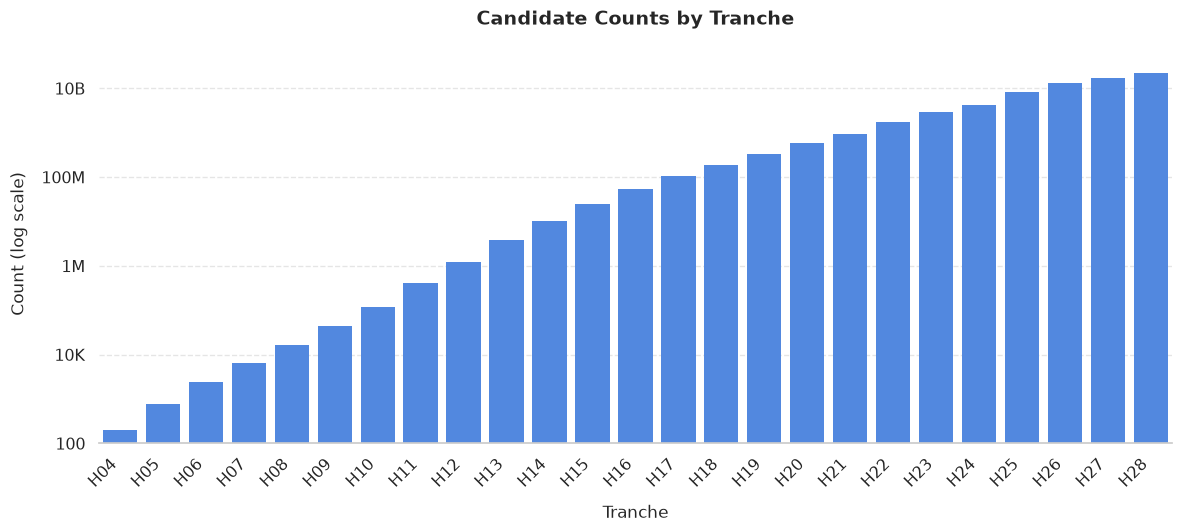

In [13]:
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.05)

fig, ax = plt.subplots(figsize=(12, 5.5))

sns.barplot(
    data=df,
    x="category",
    y="count",
    color="#3b82f6",
    edgecolor="none",
    ax=ax,
)

ax.set_yscale("log")
ax.set_ylim(100, 1e11)

sns.despine(left=True)
ax.grid(axis="x", visible=False)
ax.grid(axis="y", which="major", linestyle="--", alpha=0.5)

ax.yaxis.set_major_formatter(
    ticker.FuncFormatter(
        lambda y, _: (
            f"{y / 1e9:.0f}B"
            if y >= 1e9
            else f"{y / 1e6:.0f}M"
            if y >= 1e6
            else f"{y / 1e3:.0f}K"
            if y >= 1e3
            else f"{int(y)}"
        )
    )
)

ax.set_title("Candidate Counts by Tranche", fontsize=14, fontweight="bold", pad=14)
ax.set_xlabel("Zinc22 Tranche", labelpad=10)
ax.set_ylabel("Count (log scale)", labelpad=10)
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()